# Homework 4 – Time Series Classification (AReM)

Harsh Toshniwal

Part 1 (feature extraction) is the code from Homework 3, kept here because Part 2 uses it.

In [27]:
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.feature_selection import f_classif, RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score

warnings.filterwarnings('ignore')

## 1(a) Load the data

In [28]:
# Look at the raw file first
with open('AReM/bending1/dataset1.csv') as f:
    for i in range(8):
        print(f.readline(), end='')

# Task: bending1
# Frequency (Hz): 20
# Clock (millisecond): 250
# Duration (seconds): 120
# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,39.25,0.43,22.75,0.43,33.75,1.30
250,39.25,0.43,23.00,0.00,33.00,0.00
500,39.25,0.43,23.25,0.43,33.00,0.00


In [29]:
columns = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']

df = pd.read_csv('AReM/bending1/dataset1.csv', comment='#', header=None, names=columns)
df.head()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


In [30]:
df.shape

(480, 7)

## 1(b) Train / test split

Datasets 1 and 2 in `bending1` and `bending2`, and datasets 1, 2, and 3 in every
other folder, are test data. Everything else is training data.

In [31]:
test_directory = ['AReM/bending1/dataset1.csv' , 'AReM/bending1/dataset2.csv' ,
                  'AReM/bending2/dataset1.csv' , 'AReM/bending2/dataset2.csv' ,
                  'AReM/cycling/dataset1.csv' , 'AReM/cycling/dataset2.csv' , 'AReM/cycling/dataset3.csv' ,
                  'AReM/lying/dataset1.csv' , 'AReM/lying/dataset2.csv' , 'AReM/lying/dataset3.csv' ,
                  'AReM/sitting/dataset1.csv' , 'AReM/sitting/dataset2.csv' , 'AReM/sitting/dataset3.csv' ,
                  'AReM/standing/dataset1.csv' , 'AReM/standing/dataset2.csv' , 'AReM/standing/dataset3.csv' ,
                  'AReM/walking/dataset1.csv' , 'AReM/walking/dataset2.csv' , 'AReM/walking/dataset3.csv']

In [32]:
activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']

train_directory = []
for activity in activities:
    files = glob.glob('AReM/' + activity + '/*.csv')
    files = [f.replace('\\', '/') for f in files]
    files = sorted(files, key=lambda f: int(f.split('dataset')[1].split('.')[0]))
    for f in files:
        if f not in test_directory:
            train_directory.append(f)

print(len(train_directory), 'train files')
print(len(test_directory), 'test files')

69 train files
19 test files


## Load all files

Some files need minor cleaning: `bending2/dataset4.csv` is separated by spaces
instead of commas, and `cycling/dataset9.csv` and `cycling/dataset14.csv` have
a trailing comma on each line. Splitting on commas or whitespace and keeping
only the first 7 columns handles both.

In [33]:
train_data = []
train_labels = []

for path in train_directory:
    df = pd.read_csv(path, comment='#', header=None, sep=r'[,\s]+', engine='python',
                     usecols=range(7), names=columns)
    train_data.append(df)
    train_labels.append(path.split('/')[1])

len(train_data)

69

In [34]:
test_data = []
test_labels = []

for path in test_directory:
    df = pd.read_csv(path, comment='#', header=None, sep=r'[,\s]+', engine='python',
                     usecols=range(7), names=columns)
    test_data.append(df)
    test_labels.append(path.split('/')[1])

len(test_data)

19

### Check the loaded files

In [35]:
pd.crosstab(pd.Series(train_labels + test_labels, name='activity'),
            pd.Series(['train'] * len(train_labels) + ['test'] * len(test_labels), name='split'),
            margins=True)

split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


In [36]:
# Any file that isn't 480 x 7 or has missing values
for path, df in zip(train_directory + test_directory, train_data + test_data):
    if df.shape != (480, 7) or df.isna().sum().sum() > 0:
        print(path, df.shape, 'missing:', df.isna().sum().sum())

AReM/sitting/dataset8.csv (479, 7) missing: 0


`sitting/dataset8.csv` has 479 rows instead of 480. One missing reading won't
change the summary statistics, so it's left as is.

In [37]:
# bending2/dataset4 was space-separated, check it loaded correctly
train_data[train_directory.index('AReM/bending2/dataset4.csv')].head()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,32.50,0.50,0.0,0.0,19.0,1.00
1,250,32.50,0.50,0.0,0.0,18.5,0.50
2,500,32.75,0.43,1.0,0.0,18.0,0.00
3,750,32.50,0.50,0.0,0.0,17.5,0.50
4,1000,32.50,0.50,7.5,0.5,17.5,0.87


## 1(c) Feature Extraction

### 1(c)i. Time-domain features used in time series classification

*Note: AI (Claude) was used to research and compile this list of commonly used time-domain features for time series classification.*

Time-domain features are computed directly from the raw values of the series (no Fourier/wavelet transform). The commonly used ones are:

**Central tendency**
- **Mean** – average signal level
- **Median** – middle value, less sensitive to spikes than the mean
- **Mode** – most frequent value

**Spread / variability**
- **Standard deviation** and **variance** – how much the signal fluctuates around its mean
- **Range** – max − min
- **Interquartile range (IQR)** – Q3 − Q1, a spread measure that's robust to outliers
- **Mean absolute deviation (MAD)** – average absolute distance from the mean
- **Coefficient of variation** – std / mean, spread relative to the signal level

**Order statistics**
- **Minimum** and **maximum**
- **First quartile (Q1)** and **third quartile (Q3)**, and other percentiles (e.g. 10th, 90th)

**Shape of the distribution**
- **Skewness** – asymmetry of the values around the mean
- **Kurtosis** – how heavy the tails are / how peaky the distribution is

**Energy / magnitude**
- **Root mean square (RMS)** – overall magnitude of the signal
- **Energy** – sum of squared values
- **Sum of absolute values / signal magnitude area**

**Temporal behaviour (order of the values matters)**
- **Zero crossings / mean crossings** – how often the signal crosses zero or its mean, a rough measure of how fast it oscillates
- **Autocorrelation** at different lags – how similar the signal is to a shifted copy of itself
- **Number of peaks** and **peak-to-peak amplitude**
- **Slope / trend** – e.g. the slope of a linear fit over time
- **Mean of first differences** (mean absolute change between consecutive values)
- **Entropy** (e.g. sample entropy) – how regular or unpredictable the signal is


### 1(c)ii. Extract min, max, mean, median, std, 1st and 3rd quartile

For every instance we compute these 7 features on each of the 6 time series, giving 6 x 7 = 42 features per instance. The features are used directly without normalizing.

In [38]:
# Try it on one series first
s = train_data[0]['avg_rss12']
print('min:', s.min())
print('max:', s.max())
print('mean:', s.mean())
print('median:', s.median())
print('std:', s.std())
print('1st quart:', s.quantile(0.25))
print('3rd quart:', s.quantile(0.75))

min: 35.0
max: 47.4
mean: 43.9545
median: 44.33
std: 1.5588350663530308
1st quart: 43.0
3rd quart: 45.0


In [39]:
# Column names: min1, max1, ..., 3rd_quart6 (1-6 = the 6 time series in order)
series = columns[1:]

feature_names = []
for i in range(1, 7):
    feature_names += ['min' + str(i), 'max' + str(i), 'mean' + str(i), 'median' + str(i),
                      'std' + str(i), '1st_quart' + str(i), '3rd_quart' + str(i)]

len(feature_names)

42

In [40]:
all_data = train_data + test_data
all_labels = train_labels + test_labels

rows = []
for df in all_data:
    row = []
    for s in series:
        row += [df[s].min(), df[s].max(), df[s].mean(), df[s].median(),
                df[s].std(), df[s].quantile(0.25), df[s].quantile(0.75)]
    rows.append(row)

features = pd.DataFrame(rows, columns=feature_names)
features.index = range(1, len(features) + 1)
features.index.name = 'Instance'
features

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.500,0.0,1.79,0.493292,0.430,0.513506,0.000,0.940
2,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.330,0.0,2.18,0.613521,0.500,0.524317,0.000,1.000
3,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.250,0.0,1.79,0.383292,0.430,0.389164,0.000,0.500
4,37.00,48.00,43.454958,43.250,1.386098,42.50,45.0000,0.0,1.58,0.378083,...,2.488862,22.2500,24.000,0.0,5.26,0.679646,0.500,0.622534,0.430,0.870
5,36.25,48.00,43.969125,44.500,1.618364,43.31,44.6700,0.0,1.50,0.413125,...,3.318301,20.5000,23.750,0.0,2.96,0.555312,0.490,0.487826,0.000,0.830
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,35.50,46.25,43.174938,43.670,1.989052,42.50,44.5000,0.0,2.12,0.506583,...,2.983976,12.7500,16.500,0.0,5.72,0.911979,0.830,0.666161,0.470,1.220
85,32.75,47.00,42.760562,44.500,3.398919,41.33,45.3725,0.0,3.34,0.486167,...,4.296574,13.0000,18.565,0.0,5.73,0.842271,0.710,0.722165,0.430,1.090
86,19.33,43.50,34.227771,35.500,4.889576,30.50,37.7500,0.0,14.50,3.995729,...,3.092094,14.7500,18.670,0.0,9.74,3.394125,3.100,1.792090,2.105,4.425


In [41]:
print(features.shape)

# Keep the activity and train/test split alongside the features for later parts
features_labeled = features.copy()
features_labeled['activity'] = all_labels
features_labeled['split'] = ['train'] * len(train_data) + ['test'] * len(test_data)
features_labeled.head()

(88, 42)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,activity,split
Instance,,,,,,,,,,,,,,,,,,,,,
1,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94,bending1,train
2,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00,bending1,train
3,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50,bending1,train
4,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87,bending1,train
5,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83,bending1,train


### 1(c)iii. Standard deviation of each feature and 90% bootstrap confidence interval

First the standard deviation of each of the 42 features across the 88 instances. Then for the bootstrap, we resample the 88 instances with replacement 1000 times, recompute the standard deviation of each feature every time, and take the 5th and 95th percentiles of those 1000 values as the 90% confidence interval.

In [42]:
feature_std = features.std()
feature_std

min1          9.569975
max1          4.394362
mean1         5.335718
median1       5.440054
std1          1.772153
1st_quart1    6.153590
3rd_quart1    5.138925
min2          0.000000
max2          5.062729
mean2         1.574164
median2       1.412244
std2          0.884105
1st_quart2    0.946386
3rd_quart2    2.125266
min3          2.956462
max3          4.875137
mean3         4.008380
median3       4.036396
std3          0.946710
1st_quart3    4.220658
3rd_quart3    4.171628
min4          0.000000
max4          2.183625
mean4         1.166114
median4       1.145586
std4          0.458242
1st_quart4    0.843620
3rd_quart4    1.552504
min5          6.124001
max5          5.741238
mean5         5.675593
median5       5.813782
std5          1.024898
1st_quart5    6.096465
3rd_quart5    5.531720
min6          0.045838
max6          2.518921
mean6         1.154812
median6       1.086474
std6          0.517617
1st_quart6    0.758584
3rd_quart6    1.523599
dtype: float64

In [43]:
# Bootstrap: resample instances with replacement and recompute the std each time
np.random.seed(42)
n_boot = 1000

boot_stds = []
for b in range(n_boot):
    sample = features.sample(n=len(features), replace=True)
    boot_stds.append(sample.std())

boot_stds = pd.DataFrame(boot_stds)
boot_stds.shape

(1000, 42)

In [44]:
ci_table = pd.DataFrame({'std': feature_std,
                         'CI lower (5%)': boot_stds.quantile(0.05),
                         'CI upper (95%)': boot_stds.quantile(0.95)})
ci_table

,std,CI lower (5%),CI upper (95%)
min1,9.569975,8.238436,10.736652
max1,4.394362,3.362410,5.352420
mean1,5.335718,4.695874,5.851096
median1,5.440054,4.793015,5.990190
std1,1.772153,1.569653,1.948218
1st_quart1,6.153590,5.565222,6.623545
3rd_quart1,5.138925,4.289877,5.845192
min2,0.000000,0.000000,0.000000
max2,5.062729,4.636494,5.416213
mean2,1.574164,1.406871,1.704059


The features from the `avg_rss` series (1, 3, 5) vary much more across instances than the ones from the `var_rss` series (2, 4, 6), which is expected since the averages are on a larger scale. `min2` and `min4` are 0 in every instance, so their std and CI are exactly 0 and they carry no information for classification.

### 1(c)iv. Selecting the three most important features

A good feature should take clearly different values for different activities. To judge this we use only the training instances and:
1. look at boxplots of each feature grouped by activity,
2. compute the ANOVA F-score of each feature (between-activity variance / within-activity variance; higher means better separation),
3. check how correlated the feature types are, so we don't pick three that carry the same information.

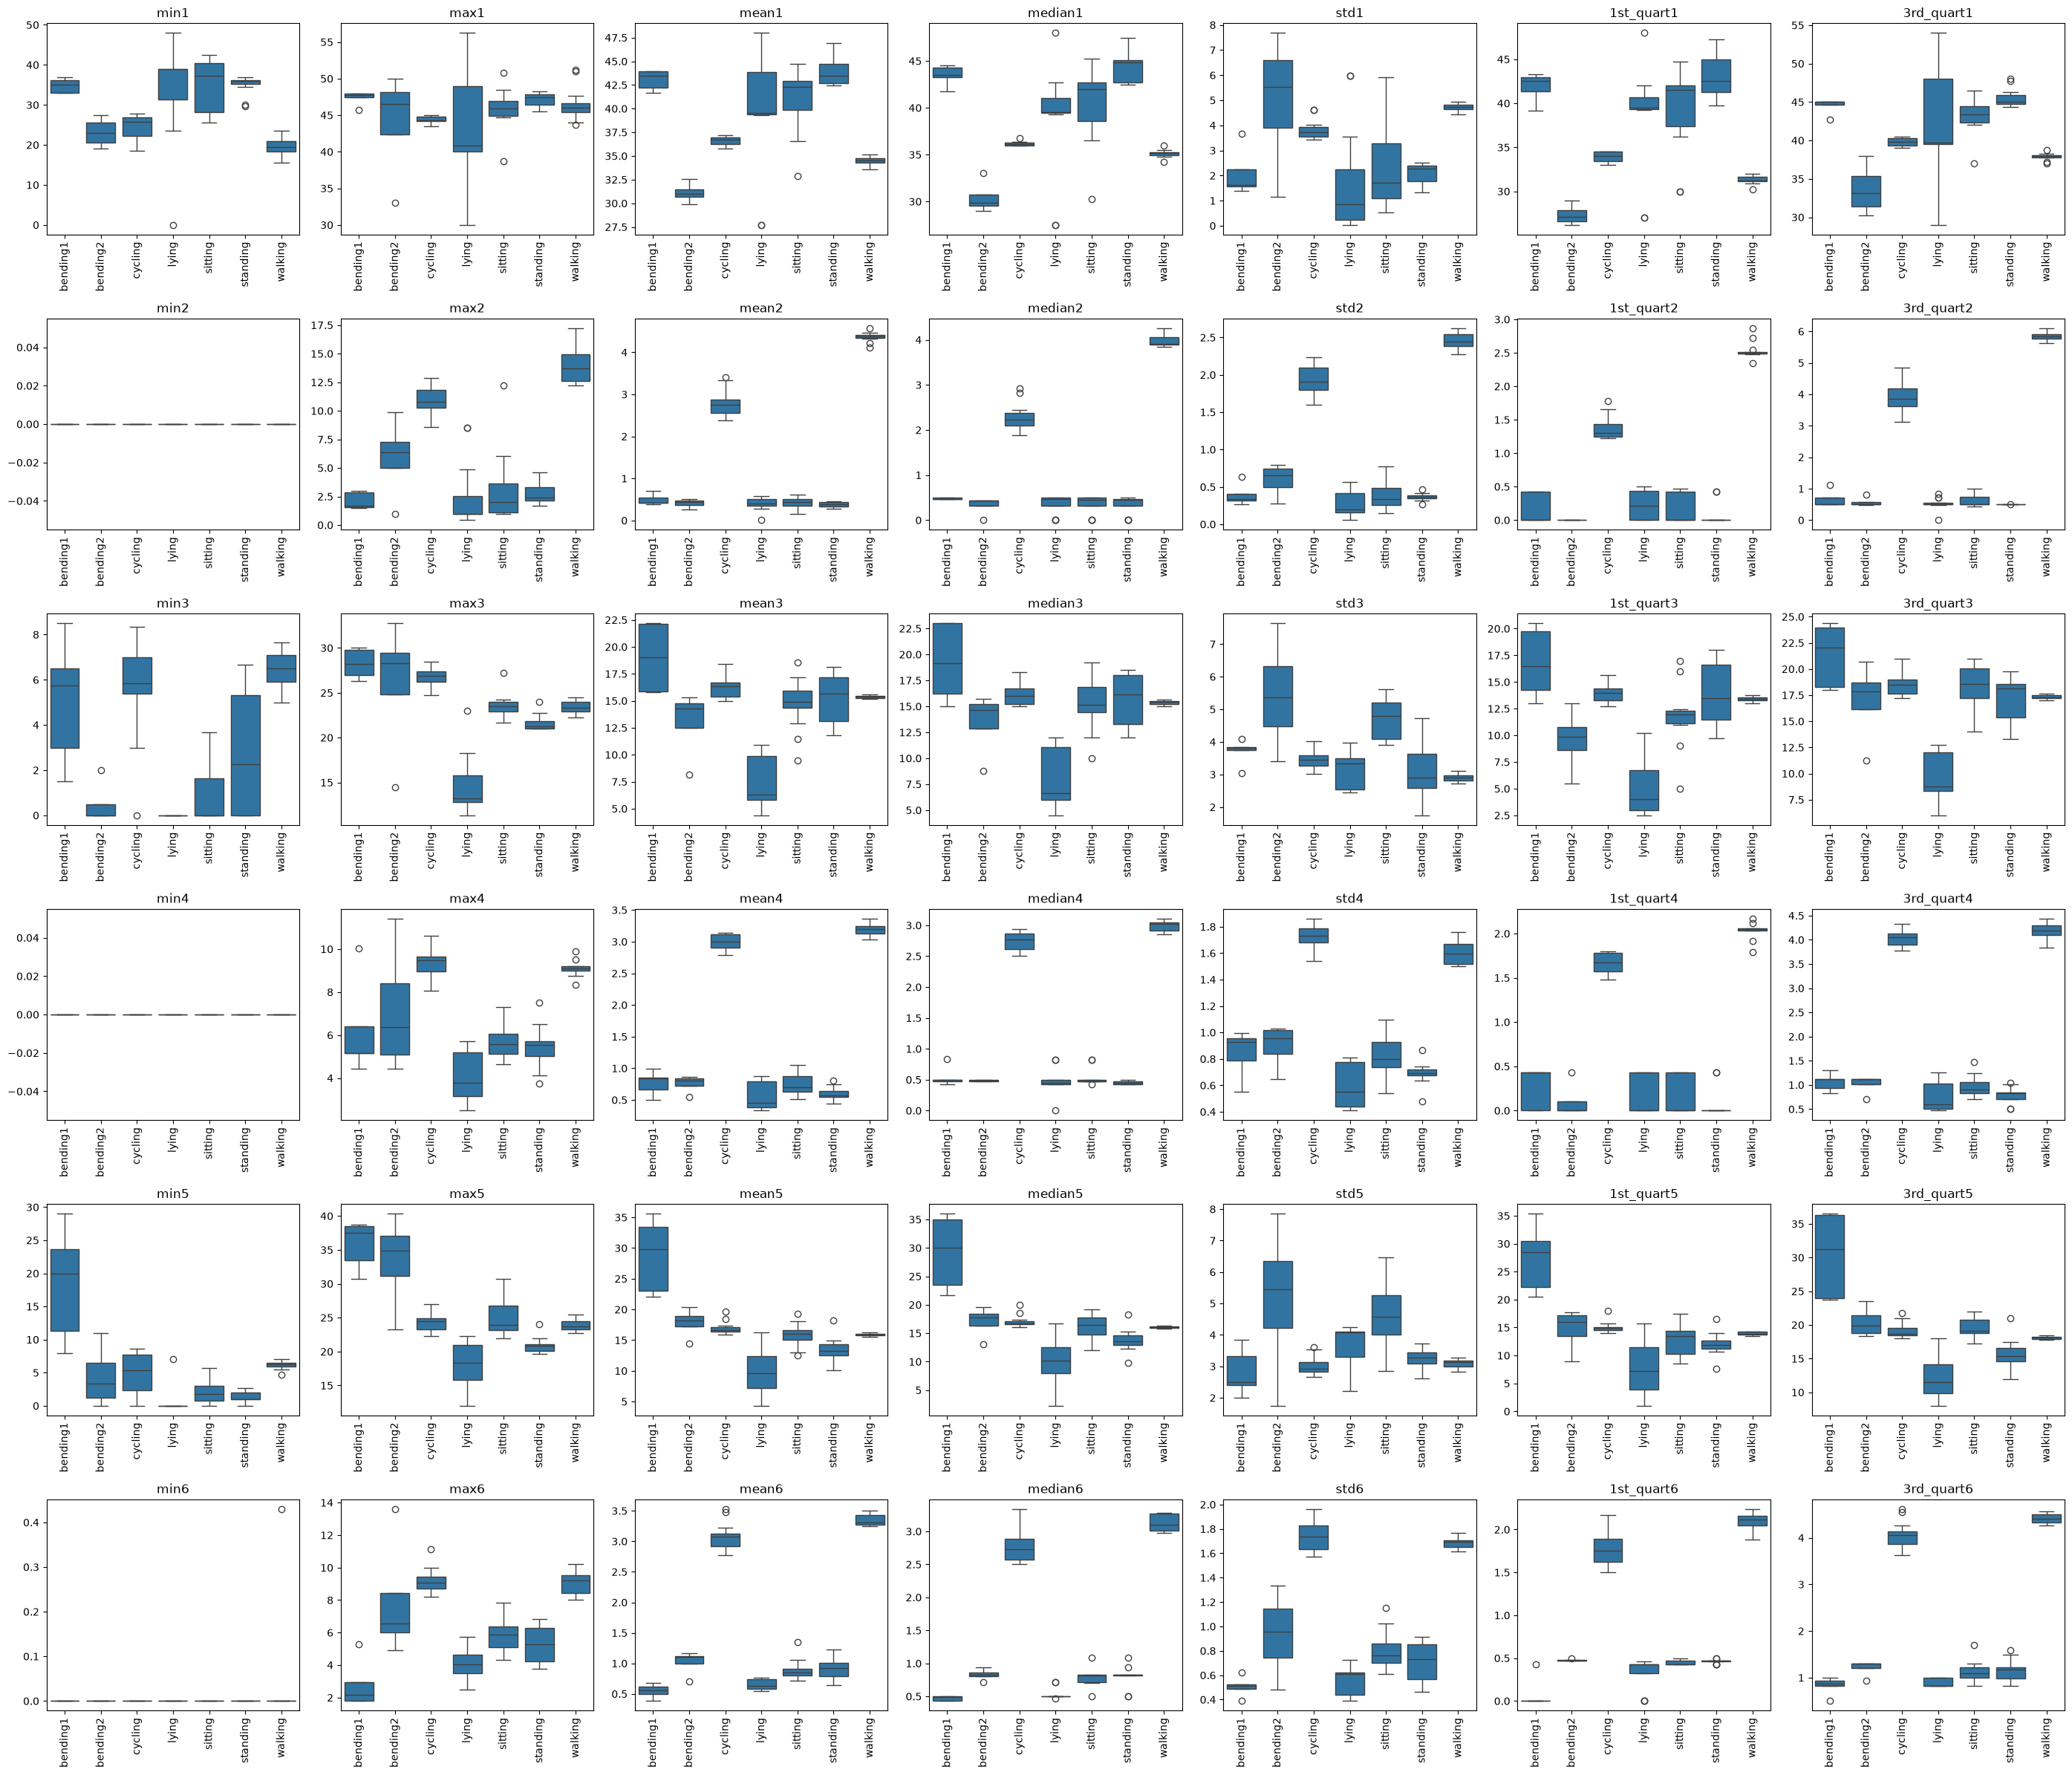

In [45]:
train_features = features_labeled[features_labeled['split'] == 'train']
feature_types = ['min', 'max', 'mean', 'median', 'std', '1st_quart', '3rd_quart']

# Rows = the 6 time series, columns = the 7 feature types
fig, axes = plt.subplots(6, 7, figsize=(28, 24))
for i in range(6):
    for j in range(7):
        col = feature_types[j] + str(i + 1)
        sns.boxplot(data=train_features, x='activity', y=col, ax=axes[i, j])
        axes[i, j].set_title(col)
        axes[i, j].set_xlabel('')
        axes[i, j].set_ylabel('')
        axes[i, j].tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

In [46]:
# ANOVA F-score of every feature against the activity label
F, p = f_classif(train_features[feature_names], train_features['activity'])
F = pd.Series(F, index=feature_names).fillna(0)   # min2 and min4 are constant -> F = 0

# Put it in a table: rows = time series, columns = feature type
f_table = pd.DataFrame(index=range(1, 7), columns=feature_types, dtype=float)
for i in range(1, 7):
    for t in feature_types:
        f_table.loc[i, t] = F[t + str(i)]
f_table.index.name = 'time series'
f_table.round(1)

,min,max,mean,median,std,1st_quart,3rd_quart
time series,,,,,,,
1,11.0,1.5,15.9,17.5,9.1,21.4,8.5
2,0.0,47.7,900.2,477.0,360.9,265.5,807.0
3,22.7,31.7,26.4,19.4,15.2,21.2,28.1
4,0.0,29.3,651.8,800.8,128.6,244.8,561.9
5,24.1,37.0,33.4,28.6,7.8,25.5,32.2
6,0.8,33.0,581.5,563.1,133.4,346.3,664.8


In [47]:
# Average F-score of each feature type over the 6 time series
f_table.mean().sort_values(ascending=False).round(1)

mean         368.2
3rd_quart    350.4
median       317.7
1st_quart    154.1
std          109.2
max           30.0
min            9.8
dtype: float64

In [48]:
# Correlation between feature types, averaged over the 6 time series
# (min2 and min4 are constant so their correlations are NaN and get skipped)
corrs = []
for i in range(1, 7):
    cols = [t + str(i) for t in feature_types]
    c = train_features[cols].corr()
    c.index = feature_types
    c.columns = feature_types
    corrs.append(c)

avg_corr = pd.concat(corrs).groupby(level=0).mean().loc[feature_types]
avg_corr.round(2)

,min,max,mean,median,std,1st_quart,3rd_quart
min,1.00,0.36,0.59,0.57,-0.32,0.60,0.52
max,0.36,1.00,0.79,0.75,0.63,0.71,0.82
mean,0.59,0.79,1.00,0.99,0.38,0.98,0.98
median,0.57,0.75,0.99,1.00,0.36,0.98,0.96
std,-0.32,0.63,0.38,0.36,1.00,0.28,0.50
1st_quart,0.60,0.71,0.98,0.98,0.28,1.00,0.93
3rd_quart,0.52,0.82,0.98,0.96,0.50,0.93,1.00


**Chosen features: mean, standard deviation, and maximum.**

- **Mean** has the highest average F-score. In the boxplots, `mean2`, `mean4` and `mean6` clearly separate cycling and walking from the rest, and `mean1`/`mean5` separate bending1, bending2 and lying.
- **Median, 1st quartile and 3rd quartile** also score high, but they are 0.93–0.99 correlated with the mean, so adding them would mostly repeat the same information.
- **Standard deviation** has the highest F-score among the features that aren't redundant with the mean (only ~0.38 correlation), so it adds new information about how much the signal fluctuates (e.g. `std1`, `std3`, `std5` single out bending2).
- **Maximum** captures the peaks of the signal (e.g. `max2`/`max6` separate walking, cycling and bending2) and is less redundant with the mean than the quartiles are.
- **Minimum** is the weakest: `min2` and `min4` are 0 for every instance and the other mins overlap a lot between activities.

## 2. Time Series Classification Part 2

### 2(a)i. Scatter plots of mean, std, max from time series 1, 2, 6 (bending vs other)

In [49]:
# bending1 and bending2 -> 'bending', everything else -> 'other'
train_features = features_labeled[features_labeled['split'] == 'train'].copy()
train_features['class'] = 'other'
train_features.loc[train_features['activity'].isin(['bending1', 'bending2']), 'class'] = 'bending'

train_features['class'].value_counts()

class
other      60
bending     9
Name: count, dtype: int64

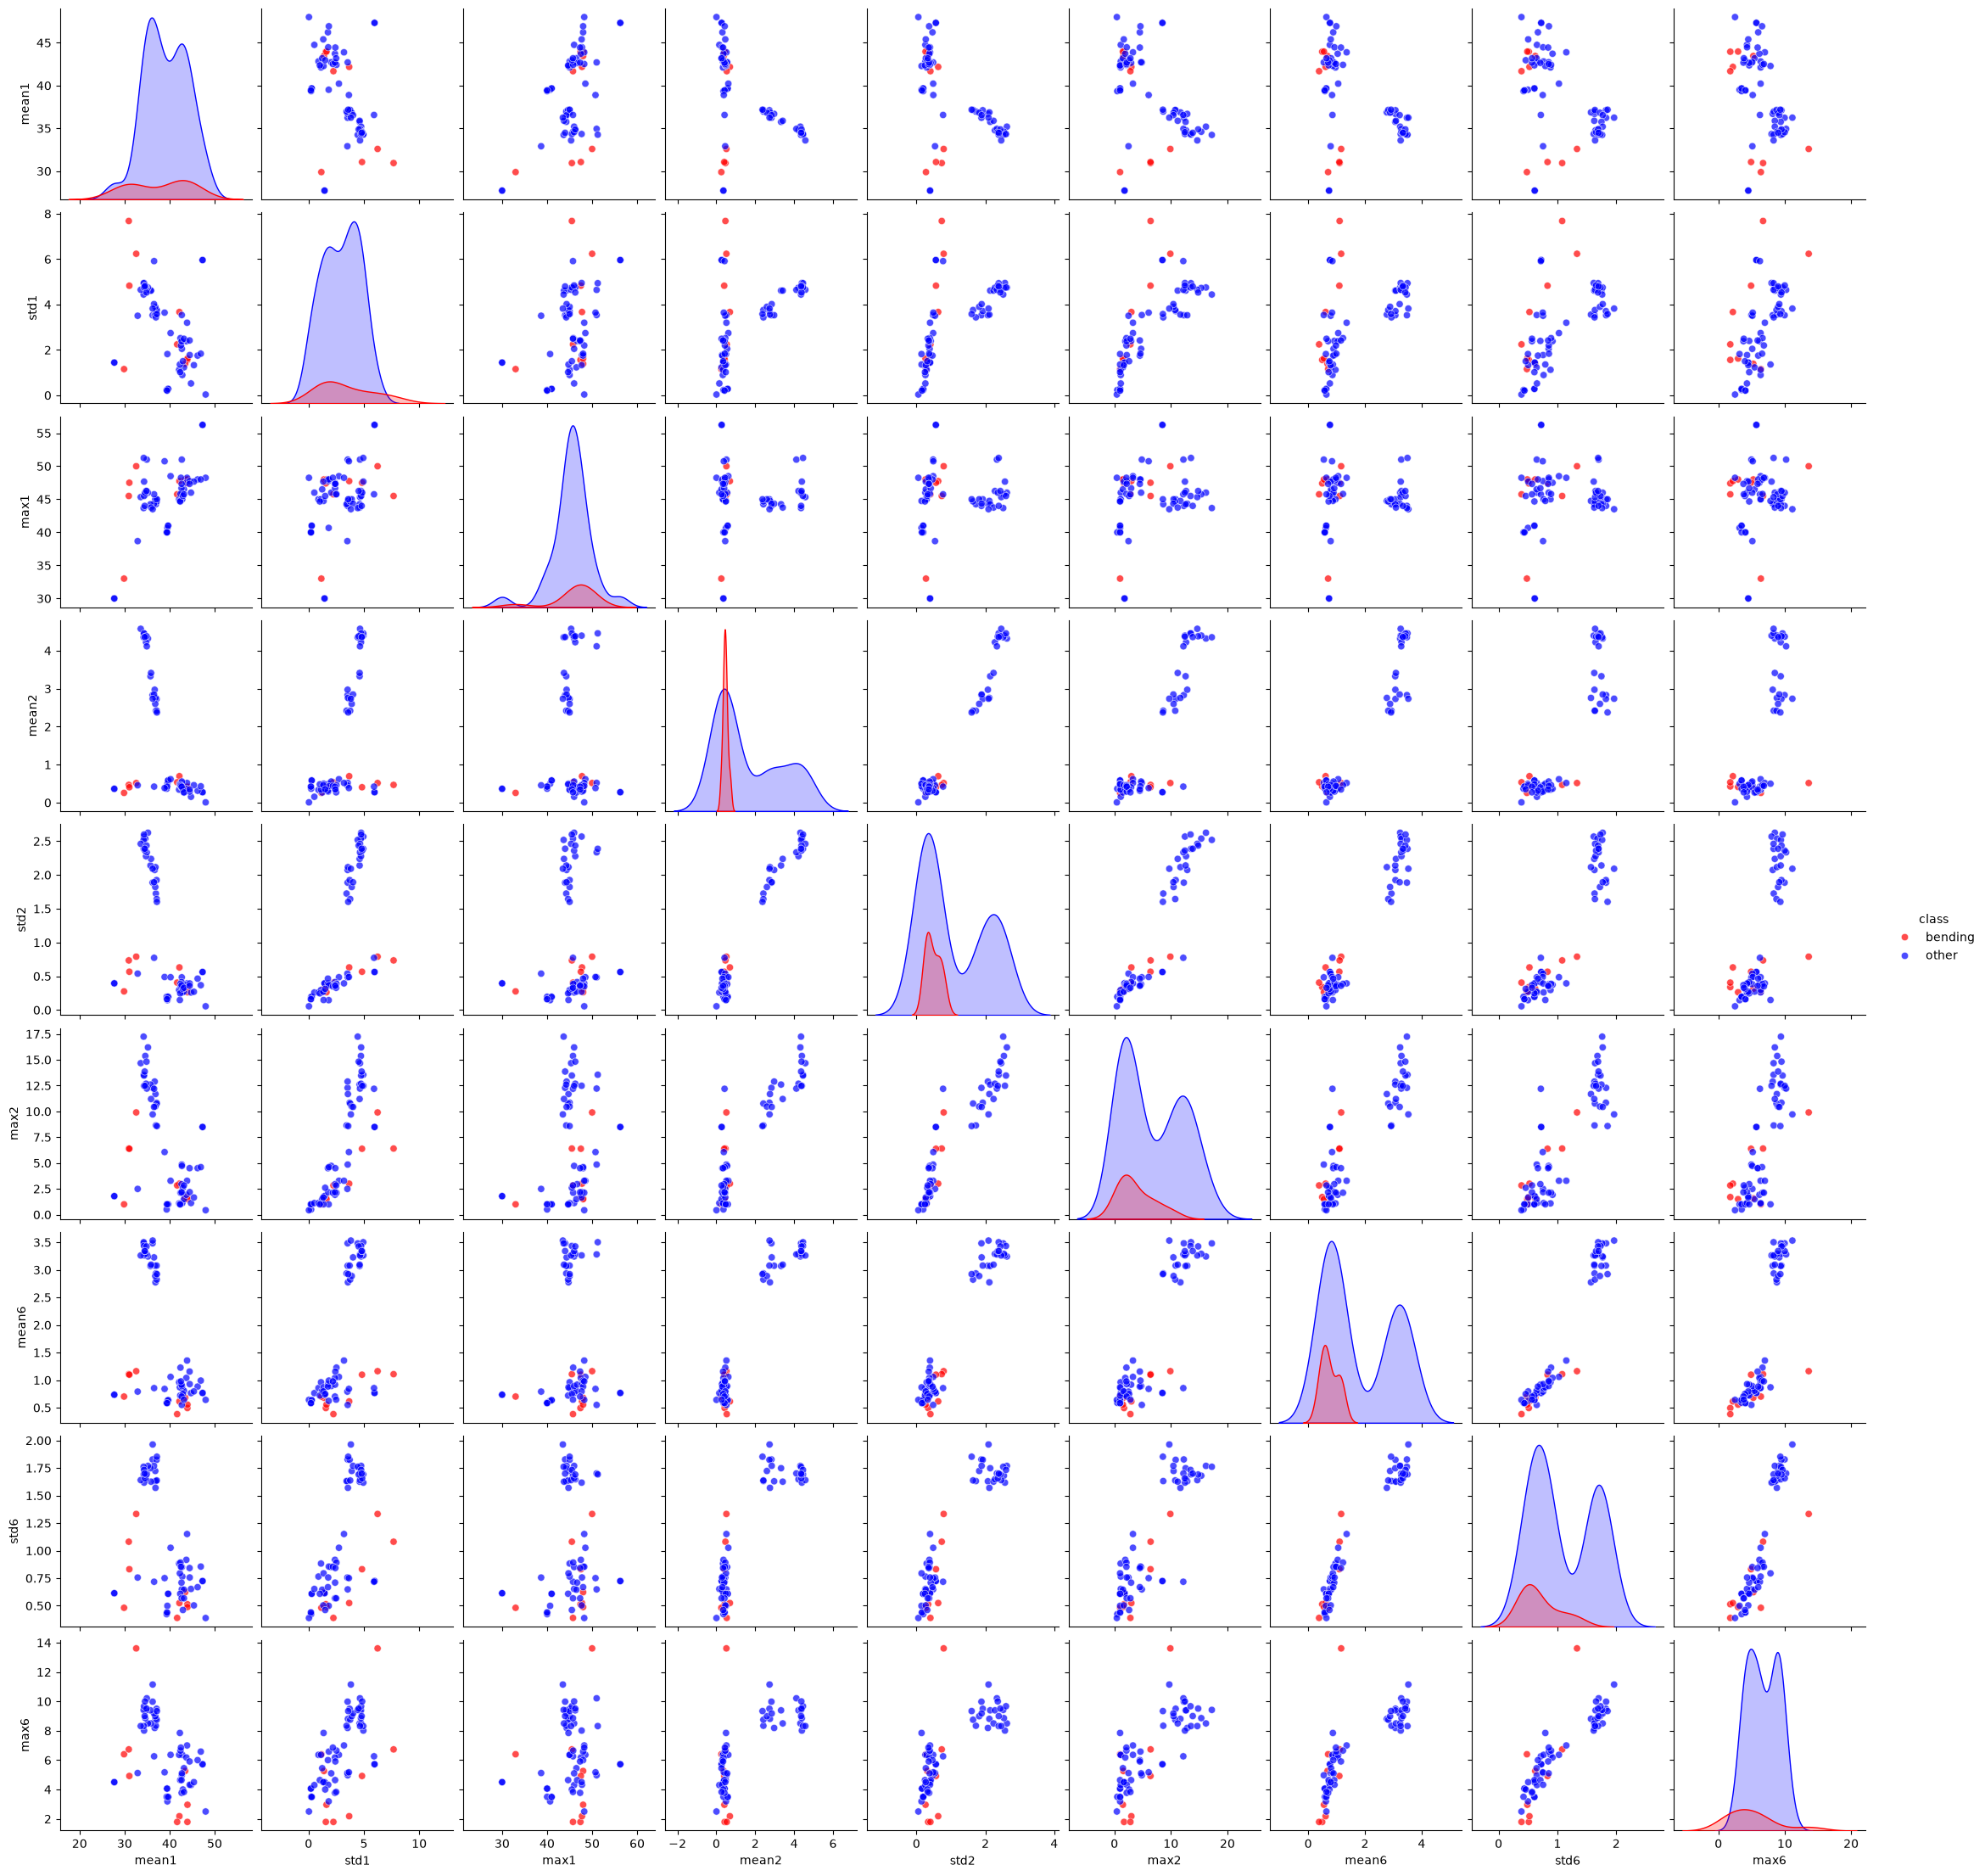

In [50]:
plot_cols = ['mean1', 'std1', 'max1',
             'mean2', 'std2', 'max2',
             'mean6', 'std6', 'max6']

sns.pairplot(train_features, vars=plot_cols, hue='class', palette={'bending': 'red', 'other': 'blue'},
             plot_kws={'alpha': 0.7})
plt.show()

### 2(a)ii. Break each time series into two halves and repeat

In [51]:
# Each of the 6 series is split into 2 halves -> 12 series per instance.
# Column names look like mean1_part1, mean1_part2, ...
rows = []
for df in train_data:
    row = {}
    for i, s in enumerate(series):
        halves = np.array_split(df[s].values, 2)
        for k, part in enumerate(halves):
            name = str(i + 1) + '_part' + str(k + 1)
            row['mean' + name] = part.mean()
            row['std' + name] = part.std(ddof=1)
            row['max' + name] = part.max()
    rows.append(row)

half_features = pd.DataFrame(rows)
half_features['class'] = train_features['class'].values
print(half_features.shape)
half_features.head()

(69, 37)


,mean1_part1,std1_part1,max1_part1,mean1_part2,std1_part2,max1_part2,mean2_part1,std2_part1,max2_part1,mean2_part2,...,mean5_part2,std5_part2,max5_part2,mean6_part1,std6_part1,max6_part1,mean6_part2,std6_part2,max6_part2,class
0,44.057167,1.556971,46.50,43.851833,1.557168,47.40,0.381042,0.329540,1.50,0.471458,...,34.883375,2.298693,38.25,0.598250,0.526656,1.79,0.388333,0.478528,1.50,bending
1,43.278875,3.473355,47.75,41.080750,3.537481,46.00,0.673292,0.634285,3.00,0.718792,...,30.965708,3.760118,38.50,0.640958,0.554542,1.53,0.586083,0.491873,2.18,bending
2,41.621208,3.118644,45.75,41.734917,0.595920,43.67,0.623083,0.489595,2.83,0.448875,...,29.635833,2.062647,36.00,0.419083,0.411200,1.79,0.347500,0.363144,1.50,bending
3,44.117042,1.359836,48.00,42.792875,1.058792,46.50,0.250042,0.314099,1.30,0.506125,...,22.850875,1.881721,26.00,0.815417,0.718016,5.26,0.543875,0.473445,4.06,bending
4,43.486208,1.281976,45.00,44.452042,1.771251,48.00,0.378667,0.284434,1.30,0.447583,...,21.882042,1.929494,26.00,0.524875,0.486847,2.28,0.585750,0.487918,2.96,bending


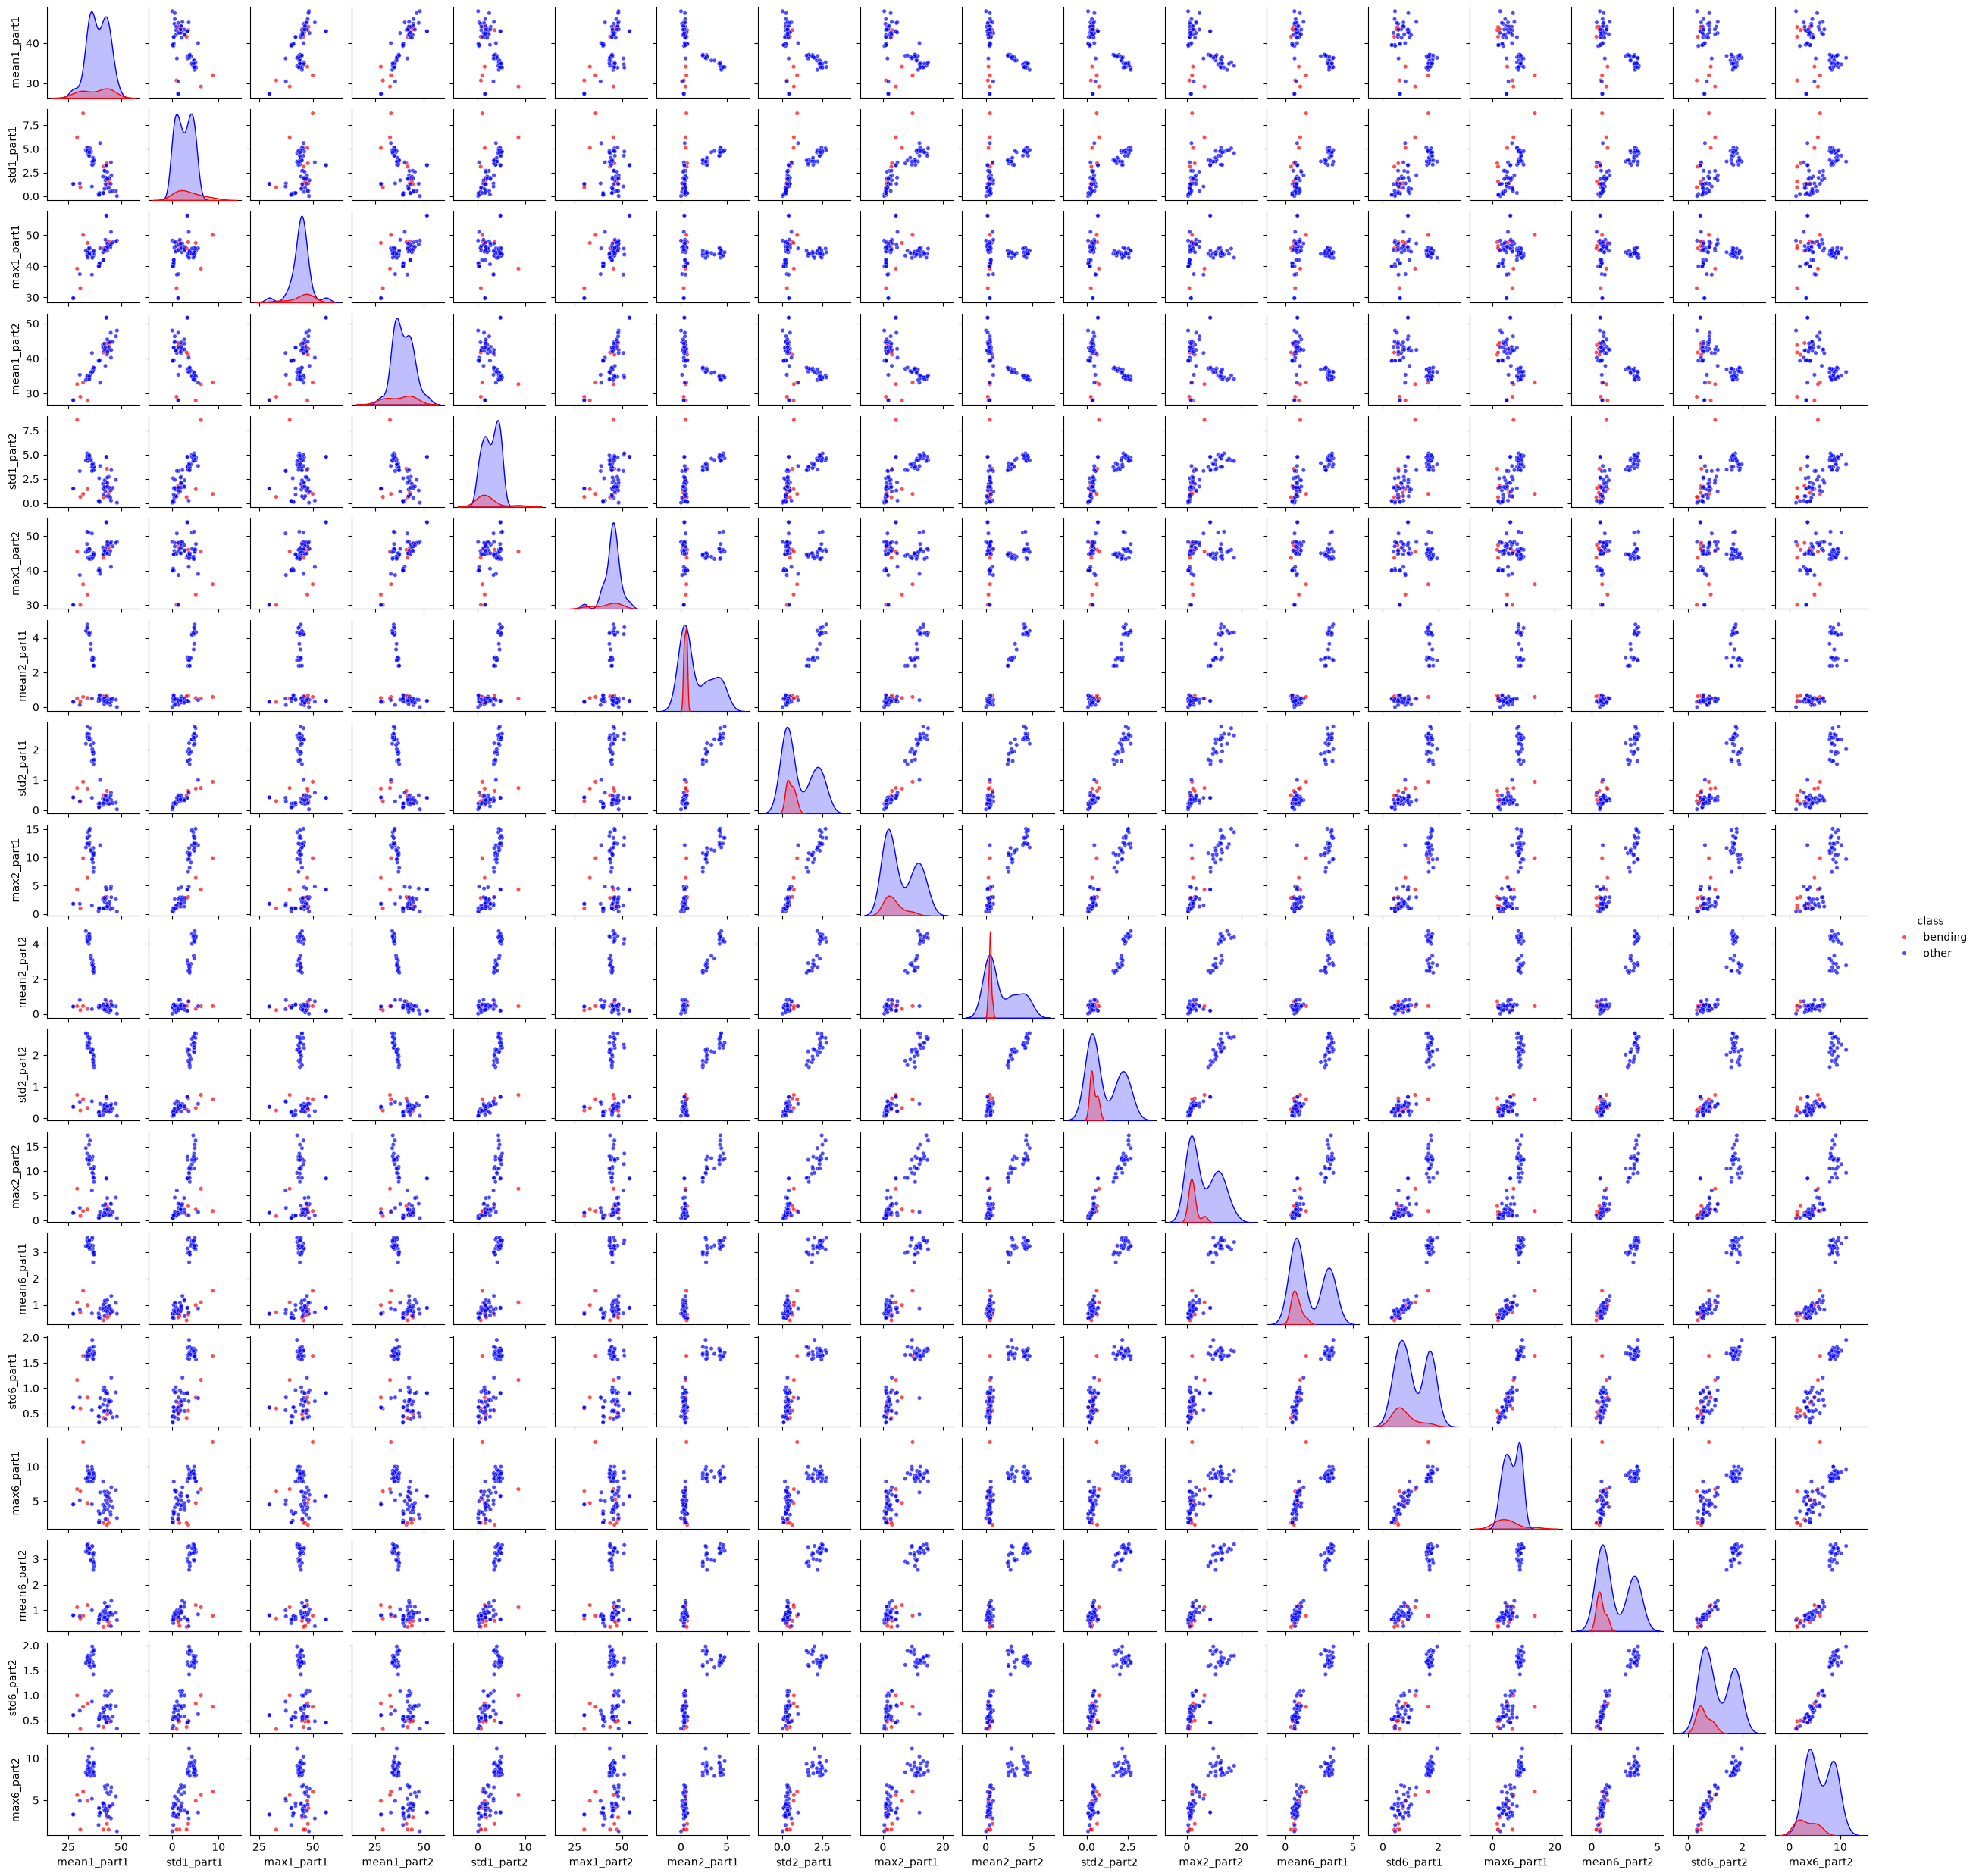

In [52]:
# Both parts of time series 1, 2 and 6 (18 features)
half_plot_cols = []
for i in [1, 2, 6]:
    for k in [1, 2]:
        for f in ['mean', 'std', 'max']:
            half_plot_cols.append(f + str(i) + '_part' + str(k))

sns.pairplot(half_features, vars=half_plot_cols, hue='class', palette={'bending': 'red', 'other': 'blue'},
             plot_kws={'alpha': 0.7, 's': 15}, height=1.4)
plt.show()

**Any considerable difference from 2(a)i?** Not really. The scatter plots for each half look almost the same as the ones for the full series: bending is still a tight group with low mean/std/max in series 2 and 6, cycling/walking still form a separate cluster, and bending still overlaps with lying, sitting and standing. The part1 and part2 versions of the same feature are strongly correlated (e.g. `mean1_part1` vs `mean1_part2` lie close to a line), because these activities are fairly steady over the 2 minutes. So splitting into two halves mostly gives us repeated information rather than a better separation.

### 2(a)iii. Break each series into l pieces, logistic regression + RFE, 5-fold CV for (l, p)

Features used: mean, std and max of every piece (the three chosen in 1(c)iv), so each instance has 6 × l × 3 features.

In [53]:
# Features for every l = 1..20, for both train and test.
# X_train_l[l] is a DataFrame with 18*l columns (same for X_test_l).
X_train_l = {}
X_test_l = {}

for l in range(1, 21):
    for data, store in [(train_data, X_train_l), (test_data, X_test_l)]:
        rows = []
        for df in data:
            row = {}
            for i, s in enumerate(series):
                pieces = np.array_split(df[s].values, l)
                for k, part in enumerate(pieces):
                    name = str(i + 1) + '_part' + str(k + 1)
                    row['mean' + name] = part.mean()
                    row['std' + name] = part.std(ddof=1)
                    row['max' + name] = part.max()
            rows.append(row)
        store[l] = pd.DataFrame(rows)

print(X_train_l[1].shape, X_train_l[20].shape)
print(X_test_l[1].shape, X_test_l[20].shape)

(69, 18) (69, 360)
(19, 18) (19, 360)


In [54]:
# 1 = bending, 0 = other
y_train = np.array([1 if 'bending' in label else 0 for label in train_labels])
y_test = np.array([1 if 'bending' in label else 0 for label in test_labels])

print('train:', np.bincount(y_train), ' test:', np.bincount(y_test))

train: [60  9]  test: [15  4]


**Right vs wrong way to do cross-validation here**

- **Wrong way:** run feature selection (RFE, or dropping features by p-value) on the *whole* training set first, and then cross-validate a logistic regression on only the selected features. The selection step has already seen the labels of the instances that later act as validation folds, so the CV accuracy is optimistically biased. With 69 instances and up to 360 features, it is easy to pick features that look good just by chance.
- **Right way:** treat feature selection as part of the model. Inside every fold, the features are selected using only that fold's training part, the model is fit on them, and it is scored on the held-out part. The value of l is also chosen by CV, since every l gives a different feature set. Here this is done with `RFECV`, which runs RFE separately inside each of the 5 folds and reports the held-out accuracy for every number of features p. Standardization is also inside the pipeline, so it is fit on each training fold only.

**Stratified CV:** there are only 9 bending vs 60 other in the training set, so a plain random 5-fold split could leave a fold with 0 or 1 bending instances. Stratified K-fold keeps the class proportions about the same in every fold (here ~2 bending per fold), so we use `StratifiedKFold`.

Logistic regression is unpenalized (`penalty=None`), as asked in footnote 3.

In [55]:
# For every l, RFECV runs RFE inside each of the 5 stratified folds and
# gives the mean held-out accuracy for every number of features p.
# (takes ~2 minutes)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
for l in range(1, 21):
    model = Pipeline([('scale', StandardScaler()),
                      ('lr', LogisticRegression(penalty=None, max_iter=100))])
    rfecv = RFECV(model, step=1, cv=cv, scoring='accuracy',
                  importance_getter='named_steps.lr.coef_')
    rfecv.fit(X_train_l[l], y_train)

    n_feats = rfecv.cv_results_['n_features']
    scores = rfecv.cv_results_['mean_test_score']
    for p, acc in zip(n_feats, scores):
        results.append({'l': l, 'p': p, 'cv_accuracy': acc})

    print('l =', l, ' features:', X_train_l[l].shape[1],
          ' best p:', n_feats[np.argmax(scores)], ' best CV acc: %.3f' % scores.max())

results = pd.DataFrame(results)

l = 1  features: 18  best p: 3  best CV acc: 0.929
l = 2  features: 36  best p: 21  best CV acc: 0.942
l = 3  features: 54  best p: 1  best CV acc: 0.986
l = 4  features: 72  best p: 1  best CV acc: 0.943
l = 5  features: 90  best p: 44  best CV acc: 0.943
l = 6  features: 108  best p: 7  best CV acc: 0.971
l = 7  features: 126  best p: 1  best CV acc: 0.957
l = 8  features: 144  best p: 13  best CV acc: 0.943
l = 9  features: 162  best p: 8  best CV acc: 0.957
l = 10  features: 180  best p: 11  best CV acc: 0.986
l = 11  features: 198  best p: 8  best CV acc: 0.957
l = 12  features: 216  best p: 31  best CV acc: 0.971
l = 13  features: 234  best p: 8  best CV acc: 0.986
l = 14  features: 252  best p: 3  best CV acc: 0.957
l = 15  features: 270  best p: 20  best CV acc: 0.971
l = 16  features: 288  best p: 14  best CV acc: 0.957
l = 17  features: 306  best p: 3  best CV acc: 0.971
l = 18  features: 324  best p: 4  best CV acc: 0.971
l = 19  features: 342  best p: 7  best CV acc: 0.971


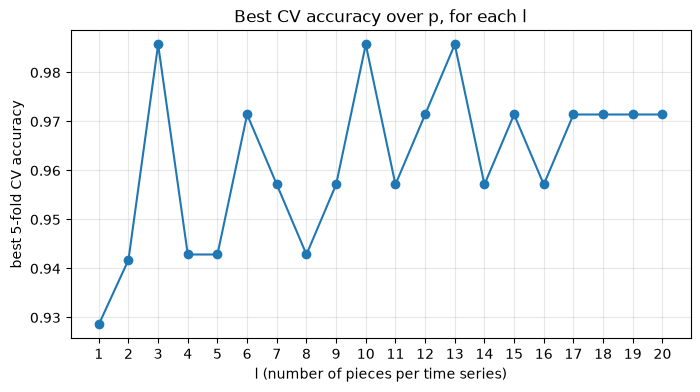

In [56]:
# Best CV accuracy for each l
best_per_l = results.groupby('l')['cv_accuracy'].max()

plt.figure(figsize=(8, 4))
plt.plot(best_per_l.index, best_per_l.values, marker='o')
plt.xticks(range(1, 21))
plt.xlabel('l (number of pieces per time series)')
plt.ylabel('best 5-fold CV accuracy')
plt.title('Best CV accuracy over p, for each l')
plt.grid(alpha=0.3)
plt.show()

In [57]:
# Best (l, p): highest CV accuracy; if there is a tie, take the smallest l and then the smallest p
results = results.sort_values(['cv_accuracy', 'l', 'p'], ascending=[False, True, True])
print(results.head(10))

best_l = int(results.iloc[0]['l'])
best_p = int(results.iloc[0]['p'])
best_cv_acc = results.iloc[0]['cv_accuracy']
print('\nBest l =', best_l, ', best p =', best_p, ', CV accuracy = %.3f' % best_cv_acc)

      l   p  cv_accuracy
54    3   1     0.985714
820  10  11     0.985714
821  10  12     0.985714
822  10  13     0.985714
823  10  14     0.985714
824  10  15     0.985714
825  10  16     0.985714
826  10  17     0.985714
827  10  18     0.985714
828  10  19     0.985714

Best l = 3 , best p = 1 , CV accuracy = 0.986


### 2(a)iv. Final model on the whole training set: confusion matrix, ROC, AUC, β's and p-values

In [58]:
# Refit RFE with the best (l, p) on all training instances
X_train_best = X_train_l[best_l]

final_model = Pipeline([('scale', StandardScaler()),
                        ('lr', LogisticRegression(penalty=None, max_iter=100))])
rfe = RFE(final_model, n_features_to_select=best_p, importance_getter='named_steps.lr.coef_')
rfe.fit(X_train_best, y_train)

selected = list(X_train_best.columns[rfe.support_])
print('Selected features:', selected)

Selected features: ['mean5_part1']


In [59]:
train_pred = rfe.predict(X_train_best)
train_prob = rfe.predict_proba(X_train_best)[:, 1]

cm = confusion_matrix(y_train, train_pred)
print(pd.DataFrame(cm, index=['true other', 'true bending'], columns=['pred other', 'pred bending']))
print('\nTrain accuracy: %.3f' % accuracy_score(y_train, train_pred))

              pred other  pred bending
true other            59             1
true bending           1             8

Train accuracy: 0.971


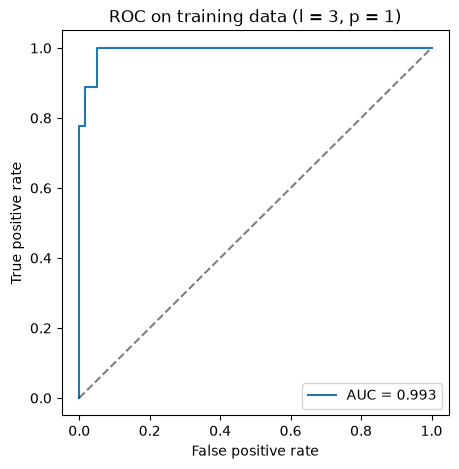

In [60]:
fpr, tpr, _ = roc_curve(y_train, train_prob)
train_auc = roc_auc_score(y_train, train_prob)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label='AUC = %.3f' % train_auc)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC on training data (l = %d, p = %d)' % (best_l, best_p))
plt.legend()
plt.show()

In [61]:
# β's and p-values: refit the same model (selected features, no penalty) with statsmodels,
# on the original (unscaled) features
logit = sm.Logit(y_train, sm.add_constant(X_train_best[selected])).fit()
print(logit.summary())

Optimization terminated successfully.
         Current function value: 0.053669
         Iterations 13
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       67
Method:                           MLE   Df Model:                            1
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.8614
Time:                        22:38:30   Log-Likelihood:                -3.7031
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 1.165e-11
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const         -56.8155     42.855     -1.326      0.185    -140.809      27.178
mean5_part1     2.9876   

### 2(a)v. Test set

In [62]:
# Test features were built with the same l (each test series split into best_l pieces)
X_test_best = X_test_l[best_l]

test_pred = rfe.predict(X_test_best)
test_prob = rfe.predict_proba(X_test_best)[:, 1]

cm_test = confusion_matrix(y_test, test_pred)
print(pd.DataFrame(cm_test, index=['true other', 'true bending'], columns=['pred other', 'pred bending']))

test_acc = accuracy_score(y_test, test_pred)
print('\nTest accuracy: %.3f' % test_acc)
print('CV accuracy:   %.3f' % best_cv_acc)
print('Test AUC:      %.3f' % roc_auc_score(y_test, test_prob))

              pred other  pred bending
true other            13             2
true bending           1             3

Test accuracy: 0.842
CV accuracy:   0.986
Test AUC:      0.900


**Test vs CV accuracy:** the test accuracy (84.2%) is clearly lower than the CV accuracy (98.6%). Some reasons:
- The CV accuracy is the *best* score out of hundreds of (l, p) combinations. Picking the maximum of many noisy estimates makes it optimistic: (l = 3, p = 1) partly won because it happened to fit these particular folds well.
- The final model uses a single feature (`mean5_part1`), which leaves little room when a test instance looks a bit different from the training ones.
- The test set is very small (19 instances, only 4 bending), so each mistake costs about 5% accuracy. Here 3 instances were misclassified.

### 2(a)vi. Are the classes well-separated enough to cause instability?

In [63]:
# Quick check with all 18 features at l = 1 (no penalty):
# if the classes are perfectly separable, the training accuracy is 100% and the
# coefficients keep growing the longer we let the optimizer run (smaller tol).
for tol in [1e-4, 1e-8, 1e-12]:
    m = Pipeline([('scale', StandardScaler()),
                  ('lr', LogisticRegression(penalty=None, max_iter=100000, tol=tol))])
    m.fit(X_train_l[1], y_train)
    print('tol =', tol, ' train acc =', accuracy_score(y_train, m.predict(X_train_l[1])),
          ' largest |beta| = %.1f' % np.abs(m.named_steps['lr'].coef_).max())

tol = 0.0001  train acc = 1.0  largest |beta| = 7.8
tol = 1e-08  train acc = 1.0  largest |beta| = 19.3
tol = 1e-12  train acc = 1.0  largest |beta| = 30.0


**Yes.** The classes are (almost) linearly separable, and this makes the logistic regression parameters unstable:
- With all 18 features the training data is perfectly separated (100% train accuracy), and the coefficients keep growing as the optimizer is allowed to run longer (largest |β| goes 7.8 → 19.3 → 30.0). The maximum likelihood estimate doesn't exist in this case — it would push the β's to infinity — so the values we get depend on when the optimizer stops. This is why footnote 5 suggests limiting `max_iter`.
- Even the final 1-feature model is close to separation: statsmodels warns about *quasi-separation*, and `mean5_part1` has a huge standard error (2.29 on a coefficient of 2.99) and a p-value of 0.19, even though it classifies 67 of 69 training instances correctly. So the p-values are not trustworthy here.

### 2(a)vii. Imbalanced classes and case-control sampling

**Yes, the classes are imbalanced:** the confusion matrices have 60 "other" vs 9 bending in train and 15 vs 4 in test (only ~13% bending).

Case-control sampling: keep all 9 bending instances (cases) and randomly sample the same number of "other" instances (controls), then fit the logistic regression on this balanced sample (same selected feature as above). Because the sample has an artificial 50% bending rate, the intercept has to be corrected back to the true rate π:

$$\hat\beta_0^* = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi}$$

where π = 9/69 is the bending rate in the full training set and π̃ = 0.5 is the rate in the case-control sample. The slope is not changed.

In [64]:
# Case-control sample: all bending + the same number of randomly chosen 'other'
np.random.seed(42)
cases = np.where(y_train == 1)[0]
controls = np.random.choice(np.where(y_train == 0)[0], size=len(cases), replace=False)
cc_idx = np.concatenate([cases, controls])

X_cc = X_train_best[selected].iloc[cc_idx]
y_cc = y_train[cc_idx]
print('case-control sample:', np.bincount(y_cc))

case-control sample: [9 9]


In [65]:
cc_model = LogisticRegression(penalty=None, max_iter=1000)
cc_model.fit(X_cc, y_cc)

pi = y_train.mean()     # true bending rate (9/69)
pi_tilde = y_cc.mean()  # bending rate in the case-control sample (0.5)

b0 = cc_model.intercept_[0]
b0_adj = b0 + np.log(pi / (1 - pi)) - np.log(pi_tilde / (1 - pi_tilde))
cc_model.intercept_ = np.array([b0_adj])

print('beta_0 before adjustment: %.3f' % b0)
print('beta_0 after adjustment:  %.3f' % b0_adj)
print('beta_1 (%s): %.3f' % (selected[0], cc_model.coef_[0][0]))

beta_0 before adjustment: -128.119
beta_0 after adjustment:  -130.017
beta_1 (mean5_part1): 7.301


Train confusion matrix:
              pred other  pred bending
true other            56             4
true bending           0             9
Train accuracy: 0.942   Train AUC: 0.993

Test confusion matrix:
              pred other  pred bending
true other            10             5
true bending           1             3
Test accuracy: 0.684   Test AUC: 0.900


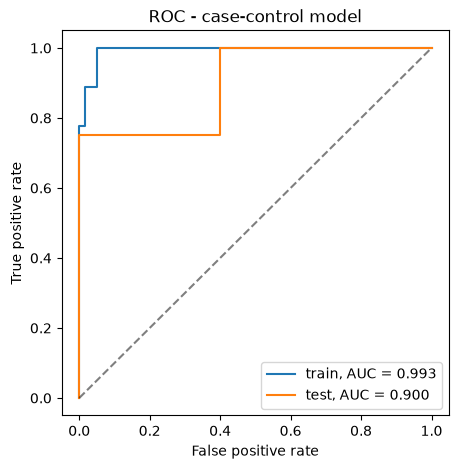

In [66]:
# Evaluate the adjusted model on the full training set (and the test set)
cc_train_prob = cc_model.predict_proba(X_train_best[selected])[:, 1]
cc_train_pred = cc_model.predict(X_train_best[selected])
cc_test_prob = cc_model.predict_proba(X_test_best[selected])[:, 1]
cc_test_pred = cc_model.predict(X_test_best[selected])

print('Train confusion matrix:')
print(pd.DataFrame(confusion_matrix(y_train, cc_train_pred),
                   index=['true other', 'true bending'], columns=['pred other', 'pred bending']))
print('Train accuracy: %.3f   Train AUC: %.3f' % (accuracy_score(y_train, cc_train_pred),
                                                  roc_auc_score(y_train, cc_train_prob)))

print('\nTest confusion matrix:')
print(pd.DataFrame(confusion_matrix(y_test, cc_test_pred),
                   index=['true other', 'true bending'], columns=['pred other', 'pred bending']))
print('Test accuracy: %.3f   Test AUC: %.3f' % (accuracy_score(y_test, cc_test_pred),
                                                roc_auc_score(y_test, cc_test_prob)))

fpr, tpr, _ = roc_curve(y_train, cc_train_prob)
fpr_t, tpr_t, _ = roc_curve(y_test, cc_test_prob)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label='train, AUC = %.3f' % roc_auc_score(y_train, cc_train_prob))
plt.plot(fpr_t, tpr_t, label='test, AUC = %.3f' % roc_auc_score(y_test, cc_test_prob))
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC - case-control model')
plt.legend()
plt.show()

The case-control model catches all 9 bending instances in train (vs 8 before), but at the cost of more false positives (4 vs 1), and on the test set its accuracy drops to 68.4%. The AUC is the same as before (0.993 train / 0.900 test) because the model still uses only `mean5_part1` with a positive slope, so it ranks the instances in the same order — only the threshold effectively moves. With just 18 instances, the case-control sample is perfectly separable, so the fitted coefficients are very unstable (β₁ = 7.3 here vs 2.99 on the full data, and they change a lot with a different random sample of controls).

## 2(b) L1-penalized logistic regression

### 2(b)i. Cross-validate over both l and C (standardized features, liblinear)

In [67]:
# Same stratified 5 folds as in 2(a)iii. For every l, GridSearchCV tries every C;
# the scaler is inside the pipeline so it is fit on the training part of each fold only.
Cs = np.logspace(-3, 3, 25)

l1_results = []
for l in range(1, 21):
    pipe = Pipeline([('scale', StandardScaler()),
                     ('lr', LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000))])
    grid = GridSearchCV(pipe, {'lr__C': Cs}, cv=cv, scoring='accuracy')
    grid.fit(X_train_l[l], y_train)

    for C, acc in zip(Cs, grid.cv_results_['mean_test_score']):
        l1_results.append({'l': l, 'C': C, 'cv_accuracy': acc})

    print('l =', l, ' best C = %.3f' % grid.best_params_['lr__C'], ' best CV acc: %.3f' % grid.best_score_)

l1_results = pd.DataFrame(l1_results)

l = 1  best C = 3.162  best CV acc: 0.971
l = 2  best C = 0.316  best CV acc: 0.957
l = 3  best C = 0.316  best CV acc: 0.971
l = 4  best C = 0.562  best CV acc: 0.971
l = 5  best C = 0.562  best CV acc: 0.942
l = 6  best C = 0.316  best CV acc: 0.957
l = 7  best C = 0.316  best CV acc: 0.942
l = 8  best C = 1000.000  best CV acc: 0.943
l = 9  best C = 0.178  best CV acc: 0.913
l = 10  best C = 1000.000  best CV acc: 0.971
l = 11  best C = 5.623  best CV acc: 0.971
l = 12  best C = 0.562  best CV acc: 0.986
l = 13  best C = 0.562  best CV acc: 0.971
l = 14  best C = 0.316  best CV acc: 0.971
l = 15  best C = 0.316  best CV acc: 0.957
l = 16  best C = 1.000  best CV acc: 0.943
l = 17  best C = 0.562  best CV acc: 0.971
l = 18  best C = 0.562  best CV acc: 0.986
l = 19  best C = 0.562  best CV acc: 0.986
l = 20  best C = 1.000  best CV acc: 0.986


In [68]:
# Best (l, C): highest CV accuracy; ties -> smallest l, then smallest C (stronger penalty, simpler model)
l1_results = l1_results.sort_values(['cv_accuracy', 'l', 'C'], ascending=[False, True, True])
print(l1_results.head(10))

l1_best_l = int(l1_results.iloc[0]['l'])
l1_best_C = l1_results.iloc[0]['C']
l1_best_cv_acc = l1_results.iloc[0]['cv_accuracy']
print('\nBest l =', l1_best_l, ', best C = %.4f' % l1_best_C, ', CV accuracy = %.3f' % l1_best_cv_acc)

      l         C  cv_accuracy
286  12  0.562341     0.985714
287  12  1.000000     0.985714
436  18  0.562341     0.985714
437  18  1.000000     0.985714
461  19  0.562341     0.985714
462  19  1.000000     0.985714
487  20  1.000000     0.985714
488  20  1.778279     0.985714
489  20  3.162278     0.985714
490  20  5.623413     0.985714

Best l = 12 , best C = 0.5623 , CV accuracy = 0.986


In [69]:
# Final L1 model with the best (l, C), fit on all training data
l1_model = Pipeline([('scale', StandardScaler()),
                     ('lr', LogisticRegression(penalty='l1', solver='liblinear', C=l1_best_C, max_iter=1000))])
l1_model.fit(X_train_l[l1_best_l], y_train)

coefs = pd.Series(l1_model.named_steps['lr'].coef_[0], index=X_train_l[l1_best_l].columns)
print('Non-zero coefficients:', (coefs != 0).sum(), 'out of', len(coefs))
print(coefs[coefs != 0].sort_values())

Non-zero coefficients: 5 out of 216
max1_part7     -0.521245
max6_part11    -0.490154
std3_part3      0.015306
mean5_part11    0.188233
mean5_part2     1.855661
dtype: float64


Train confusion matrix:
              pred other  pred bending
true other            60             0
true bending           0             9
Train accuracy: 1.000   Train AUC: 1.000

Test confusion matrix:
              pred other  pred bending
true other            15             0
true bending           1             3
Test accuracy: 0.947   Test AUC: 0.983
CV accuracy:   0.986


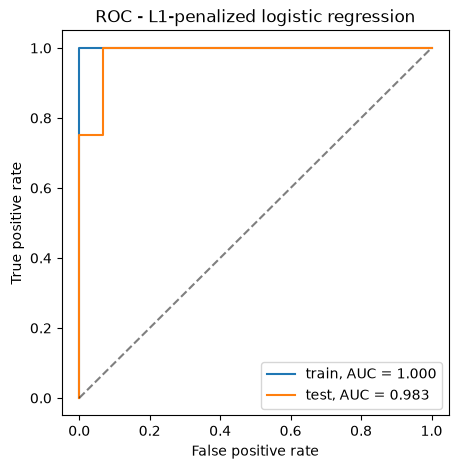

In [70]:
l1_train_pred = l1_model.predict(X_train_l[l1_best_l])
l1_train_prob = l1_model.predict_proba(X_train_l[l1_best_l])[:, 1]
l1_test_pred = l1_model.predict(X_test_l[l1_best_l])
l1_test_prob = l1_model.predict_proba(X_test_l[l1_best_l])[:, 1]

print('Train confusion matrix:')
print(pd.DataFrame(confusion_matrix(y_train, l1_train_pred),
                   index=['true other', 'true bending'], columns=['pred other', 'pred bending']))
print('Train accuracy: %.3f   Train AUC: %.3f' % (accuracy_score(y_train, l1_train_pred),
                                                  roc_auc_score(y_train, l1_train_prob)))

print('\nTest confusion matrix:')
print(pd.DataFrame(confusion_matrix(y_test, l1_test_pred),
                   index=['true other', 'true bending'], columns=['pred other', 'pred bending']))
print('Test accuracy: %.3f   Test AUC: %.3f' % (accuracy_score(y_test, l1_test_pred),
                                                roc_auc_score(y_test, l1_test_prob)))
print('CV accuracy:   %.3f' % l1_best_cv_acc)

fpr, tpr, _ = roc_curve(y_train, l1_train_prob)
fpr_t, tpr_t, _ = roc_curve(y_test, l1_test_prob)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label='train, AUC = %.3f' % roc_auc_score(y_train, l1_train_prob))
plt.plot(fpr_t, tpr_t, label='test, AUC = %.3f' % roc_auc_score(y_test, l1_test_prob))
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC - L1-penalized logistic regression')
plt.legend()
plt.show()

### 2(b)ii. L1-penalized vs variable selection with p-values / RFE

**Which performs better?** The L1-penalized model. Both reach the same CV accuracy (0.986), but L1 does better on the test set: 94.7% accuracy and AUC 0.983, against 84.2% and 0.900 for the RFE model (1 mistake instead of 3). With only 19 test instances this is a difference of 2 instances, so it shouldn't be over-interpreted. L1 picked l = 12 and kept 5 of the 216 features, while RFE picked l = 3 with a single feature. The penalty shrinks the coefficients, so it also avoids the instability from the (near) separation seen in 2(a)vi, and it can keep a few useful features with small weights instead of relying on one feature with a huge, unreliable coefficient.

**Which is easier to implement?** Also L1. Feature selection and fitting happen in one step — the penalty sets most coefficients to exactly zero — and the only thing to tune is C, which `GridSearchCV` handles directly. The p-value approach needs a separate package (statsmodels) for the p-values, the p-values themselves are unreliable when the classes are separable, and RFE has to refit the model many times for every candidate number of features p.

## 2(c) Multi-class classification

### 2(c)i. L1-penalized multinomial logistic regression (CV over l and C)

`liblinear` only does one-vs-rest, so the `saga` solver is used here, which supports a true multinomial model with an L1 penalty.

In [71]:
# All 7 activities as labels
y_train_mc = np.array(train_labels)
y_test_mc = np.array(test_labels)
print(pd.Series(y_train_mc).value_counts())

cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64


In [72]:
# Same idea as 2(b)i: for each l, grid search over C with stratified 5-fold CV.
# (bending2 has only 4 training instances, so one fold won't have a bending2 instance)
Cs_mc = np.logspace(-2, 2, 13)

mc_results = []
for l in range(1, 21):
    pipe = Pipeline([('scale', StandardScaler()),
                     ('lr', LogisticRegression(penalty='l1', solver='saga', max_iter=2000, tol=1e-3, random_state=42))])
    grid = GridSearchCV(pipe, {'lr__C': Cs_mc}, cv=cv, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train_l[l], y_train_mc)

    for C, acc in zip(Cs_mc, grid.cv_results_['mean_test_score']):
        mc_results.append({'l': l, 'C': C, 'cv_accuracy': acc})

    print('l =', l, ' best C = %.3f' % grid.best_params_['lr__C'], ' best CV acc: %.3f' % grid.best_score_)

mc_results = pd.DataFrame(mc_results)

l = 1  best C = 1.000  best CV acc: 0.899
l = 2  best C = 46.416  best CV acc: 0.856
l = 3  best C = 46.416  best CV acc: 0.827
l = 4  best C = 4.642  best CV acc: 0.843
l = 5  best C = 10.000  best CV acc: 0.857
l = 6  best C = 21.544  best CV acc: 0.886
l = 7  best C = 21.544  best CV acc: 0.885
l = 8  best C = 21.544  best CV acc: 0.799
l = 9  best C = 21.544  best CV acc: 0.857
l = 10  best C = 2.154  best CV acc: 0.813
l = 11  best C = 46.416  best CV acc: 0.886
l = 12  best C = 100.000  best CV acc: 0.886
l = 13  best C = 100.000  best CV acc: 0.843
l = 14  best C = 46.416  best CV acc: 0.827
l = 15  best C = 2.154  best CV acc: 0.871
l = 16  best C = 0.464  best CV acc: 0.814
l = 17  best C = 0.464  best CV acc: 0.871
l = 18  best C = 0.464  best CV acc: 0.856
l = 19  best C = 46.416  best CV acc: 0.842
l = 20  best C = 46.416  best CV acc: 0.857


In [73]:
# Best (l, C): highest CV accuracy; ties -> smallest l, then smallest C
mc_results = mc_results.sort_values(['cv_accuracy', 'l', 'C'], ascending=[False, True, True])
print(mc_results.head(5))

mc_best_l = int(mc_results.iloc[0]['l'])
mc_best_C = mc_results.iloc[0]['C']
mc_best_cv_acc = mc_results.iloc[0]['cv_accuracy']
print('\nBest l =', mc_best_l, ', best C = %.4f' % mc_best_C, ', CV accuracy = %.3f' % mc_best_cv_acc)

      l           C  cv_accuracy
6     1    1.000000     0.898901
7     1    2.154435     0.898901
75    6   21.544347     0.885714
141  11   46.415888     0.885714
142  11  100.000000     0.885714

Best l = 1 , best C = 1.0000 , CV accuracy = 0.899


In [74]:
# Final multinomial model on all training data, then the test set
mc_model = Pipeline([('scale', StandardScaler()),
                     ('lr', LogisticRegression(penalty='l1', solver='saga', C=mc_best_C, max_iter=2000, tol=1e-3, random_state=42))])
mc_model.fit(X_train_l[mc_best_l], y_train_mc)

mc_test_pred = mc_model.predict(X_test_l[mc_best_l])
mc_test_prob = mc_model.predict_proba(X_test_l[mc_best_l])

print('Non-zero features:', (np.abs(mc_model.named_steps['lr'].coef_).sum(axis=0) != 0).sum(),
      'out of', X_train_l[mc_best_l].shape[1])
print('Test accuracy: %.3f' % accuracy_score(y_test_mc, mc_test_pred))
print('Test error:    %.3f' % (1 - accuracy_score(y_test_mc, mc_test_pred)))

Non-zero features: 14 out of 18
Test accuracy: 0.947
Test error:    0.053


**Confusion matrix and ROC for more than two classes**

- **Confusion matrix:** a K × K table (here 7 × 7). Row i, column j counts the instances whose true class is i and that were predicted as class j. The diagonal holds the correct predictions and the off-diagonal cells show which activities get confused with which.
- **ROC curve:** ROC is defined for two classes, so for K classes it is usually done **one-vs-rest**: for each class k, treat "class k" as positive and all other classes as negative, and use the predicted probability of class k as the score. This gives K ROC curves and K AUCs. They can be summarised by the **macro-average** AUC (plain average of the K AUCs) or the **micro-average** (stack all K binary problems together and compute one ROC curve).

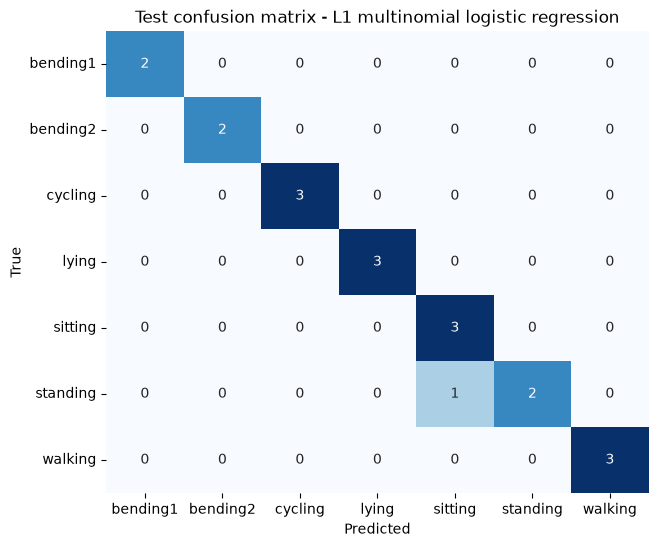

In [75]:
classes = mc_model.classes_

cm_mc = confusion_matrix(y_test_mc, mc_test_pred, labels=classes)
plt.figure(figsize=(7, 6))
sns.heatmap(cm_mc, annot=True, cmap='Blues', xticklabels=classes, yticklabels=classes, cbar=False)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Test confusion matrix - L1 multinomial logistic regression')
plt.show()

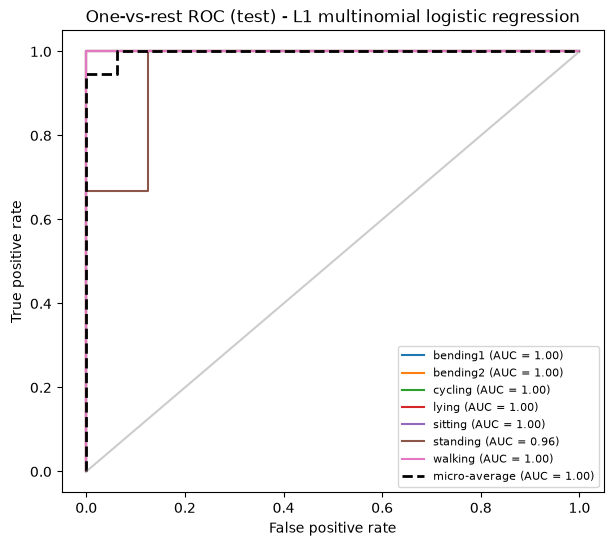

Macro-average AUC: 0.994


In [76]:
# One-vs-rest ROC on the test set: one curve per class + micro-average
y_test_bin = label_binarize(y_test_mc, classes=classes)

plt.figure(figsize=(7, 6))
for k, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, k], mc_test_prob[:, k])
    plt.plot(fpr, tpr, label='%s (AUC = %.2f)' % (c, roc_auc_score(y_test_bin[:, k], mc_test_prob[:, k])))

fpr, tpr, _ = roc_curve(y_test_bin.ravel(), mc_test_prob.ravel())
plt.plot(fpr, tpr, 'k--', linewidth=2,
         label='micro-average (AUC = %.2f)' % roc_auc_score(y_test_bin.ravel(), mc_test_prob.ravel()))
plt.plot([0, 1], [0, 1], color='grey', alpha=0.4)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('One-vs-rest ROC (test) - L1 multinomial logistic regression')
plt.legend(fontsize=8)
plt.show()

print('Macro-average AUC: %.3f' % roc_auc_score(y_test_mc, mc_test_prob, multi_class='ovr', average='macro'))

### 2(c)ii. Naïve Bayes with Gaussian and Multinomial priors

Same procedure: l is chosen with the same stratified 5-fold CV. Gaussian NB has no penalty to tune. Multinomial NB needs non-negative features, so the features are scaled to [0, 1] with `MinMaxScaler` (inside the pipeline), and its smoothing parameter α is tuned together with l.

In [77]:
# Gaussian NB: 5-fold CV accuracy for every l
gnb_results = []
for l in range(1, 21):
    scores = cross_val_score(GaussianNB(), X_train_l[l], y_train_mc, cv=cv, scoring='accuracy')
    gnb_results.append({'l': l, 'cv_accuracy': scores.mean()})
gnb_results = pd.DataFrame(gnb_results)

gnb_best = gnb_results.sort_values(['cv_accuracy', 'l'], ascending=[False, True]).iloc[0]
gnb_best_l = int(gnb_best['l'])
print(gnb_results.set_index('l')['cv_accuracy'].round(3).to_frame().T)
print('\nGaussian NB: best l =', gnb_best_l, ', CV accuracy = %.3f' % gnb_best['cv_accuracy'])

l               1      2      3      4      5      6      7      8      9   \
cv_accuracy  0.886  0.856  0.842  0.856  0.827  0.856  0.813  0.799  0.769   

l               10     11     12     13     14    15     16     17    18  \
cv_accuracy  0.755  0.785  0.799  0.697  0.742  0.74  0.741  0.769  0.71   

l               19     20  
cv_accuracy  0.741  0.769  

Gaussian NB: best l = 1 , CV accuracy = 0.886


In [78]:
# Multinomial NB: features scaled to [0, 1] (clip=True so test values outside the
# training range don't become negative); grid search over alpha for every l
alphas = [0.001, 0.01, 0.1, 0.5, 1.0, 2.0]

mnb_results = []
for l in range(1, 21):
    pipe = Pipeline([('scale', MinMaxScaler(clip=True)), ('nb', MultinomialNB())])
    grid = GridSearchCV(pipe, {'nb__alpha': alphas}, cv=cv, scoring='accuracy')
    grid.fit(X_train_l[l], y_train_mc)
    for a, acc in zip(alphas, grid.cv_results_['mean_test_score']):
        mnb_results.append({'l': l, 'alpha': a, 'cv_accuracy': acc})
mnb_results = pd.DataFrame(mnb_results)

mnb_best = mnb_results.sort_values(['cv_accuracy', 'l', 'alpha'], ascending=[False, True, False]).iloc[0]
mnb_best_l = int(mnb_best['l'])
mnb_best_alpha = mnb_best['alpha']
print(mnb_results.groupby('l')['cv_accuracy'].max().round(3).to_frame().T)
print('\nMultinomial NB: best l =', mnb_best_l, ', alpha =', mnb_best_alpha,
      ', CV accuracy = %.3f' % mnb_best['cv_accuracy'])

l               1     2     3      4      5      6      7      8     9   \
cv_accuracy  0.697  0.77  0.77  0.742  0.771  0.786  0.785  0.769  0.77   

l               10     11     12    13     14    15     16     17     18  \
cv_accuracy  0.799  0.769  0.785  0.77  0.727  0.77  0.755  0.785  0.726   

l               19     20  
cv_accuracy  0.742  0.756  

Multinomial NB: best l = 10 , alpha = 0.1 , CV accuracy = 0.799


In [79]:
# Fit both on all training data with their best settings and test them
gnb = GaussianNB()
gnb.fit(X_train_l[gnb_best_l], y_train_mc)
gnb_pred = gnb.predict(X_test_l[gnb_best_l])
gnb_prob = gnb.predict_proba(X_test_l[gnb_best_l])

mnb = Pipeline([('scale', MinMaxScaler(clip=True)), ('nb', MultinomialNB(alpha=mnb_best_alpha))])
mnb.fit(X_train_l[mnb_best_l], y_train_mc)
mnb_pred = mnb.predict(X_test_l[mnb_best_l])
mnb_prob = mnb.predict_proba(X_test_l[mnb_best_l])

print('Gaussian NB    - test accuracy: %.3f, test error: %.3f, macro AUC: %.3f'
      % (accuracy_score(y_test_mc, gnb_pred), 1 - accuracy_score(y_test_mc, gnb_pred),
         roc_auc_score(y_test_mc, gnb_prob, multi_class='ovr')))
print('Multinomial NB - test accuracy: %.3f, test error: %.3f, macro AUC: %.3f'
      % (accuracy_score(y_test_mc, mnb_pred), 1 - accuracy_score(y_test_mc, mnb_pred),
         roc_auc_score(y_test_mc, mnb_prob, multi_class='ovr')))

Gaussian NB    - test accuracy: 0.895, test error: 0.105, macro AUC: 0.997
Multinomial NB - test accuracy: 0.789, test error: 0.211, macro AUC: 0.957


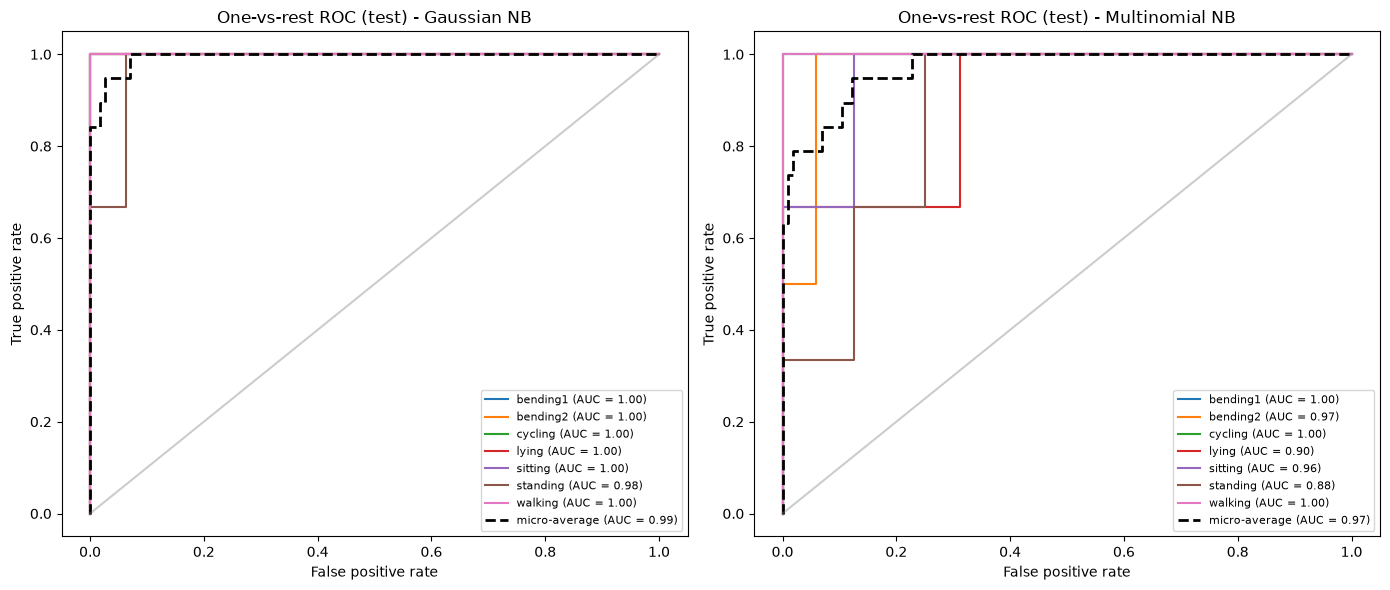

In [80]:
# One-vs-rest ROC curves on the test set
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, prob, name in [(axes[0], gnb_prob, 'Gaussian NB'), (axes[1], mnb_prob, 'Multinomial NB')]:
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, k], prob[:, k])
        ax.plot(fpr, tpr, label='%s (AUC = %.2f)' % (c, roc_auc_score(y_test_bin[:, k], prob[:, k])))
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), prob.ravel())
    ax.plot(fpr, tpr, 'k--', linewidth=2,
            label='micro-average (AUC = %.2f)' % roc_auc_score(y_test_bin.ravel(), prob.ravel()))
    ax.plot([0, 1], [0, 1], color='grey', alpha=0.4)
    ax.set_xlabel('False positive rate')
    ax.set_ylabel('True positive rate')
    ax.set_title('One-vs-rest ROC (test) - ' + name)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

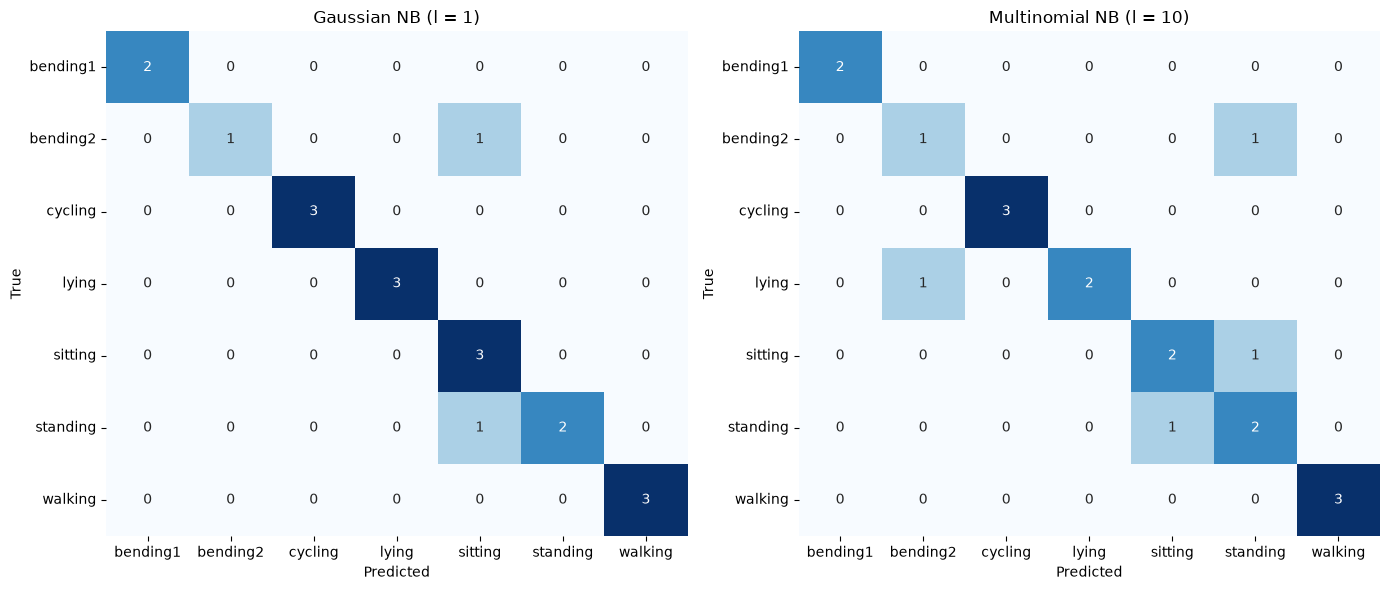

In [81]:
# Test confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, pred, name in [(axes[0], gnb_pred, 'Gaussian NB (l = %d)' % gnb_best_l),
                       (axes[1], mnb_pred, 'Multinomial NB (l = %d)' % mnb_best_l)]:
    sns.heatmap(confusion_matrix(y_test_mc, pred, labels=classes), annot=True, cmap='Blues',
                xticklabels=classes, yticklabels=classes, cbar=False, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Gaussian vs Multinomial NB:** Gaussian NB is clearly better. It picks l = 1 with a CV accuracy of 0.886 and gets a test error of 0.105 (macro AUC 0.997), while Multinomial NB picks l = 10 (α = 0.1) with a CV accuracy of 0.799 and a test error of 0.211 (macro AUC 0.957). Our features (means, stds, maxima of the signals) are continuous values, and within one activity they are roughly bell-shaped, which is what the Gaussian prior assumes. The multinomial prior is designed for counts / frequencies (like word counts): after min-max scaling the features are treated as "counts", and the model only really uses their relative sizes within an instance, which throws away information about their actual levels. Both models still confuse the similar static activities (sitting / standing, and one bending2 instance).

### 2(c)iii. Which method is better for multi-class classification?

**L1-penalized multinomial logistic regression** is the best here. It has the highest CV accuracy (0.899) and the highest test accuracy (0.947, only 1 of 19 test instances wrong — a standing instance predicted as sitting). Gaussian NB is a close second (CV 0.886, test accuracy 0.895) and its probabilities rank the classes about as well (macro AUC 0.997 vs 0.994), but it makes one more mistake because its independence assumption ignores the strong correlations between features (e.g. mean and max of the same series). Multinomial NB is clearly the worst (CV 0.799, test accuracy 0.789) because its prior doesn't fit continuous features. With only 19 test instances the gap between logistic regression and Gaussian NB is just one instance, but logistic regression is also ahead in CV, so it is the better choice.

## 3. ISLR 4.8.3

*Note: the answers to the ISLR questions (3 and 4) were worked out with the help of AI tools (Gemini and Claude).*

QDA with one feature: in class k, $X \sim N(\mu_k, \sigma_k^2)$, with class-specific variance $\sigma_k^2$, and prior $\pi_k$.

The Bayes classifier assigns $x$ to the class with the largest posterior
$$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

The denominator is the same for every class, so this is the same as picking the largest $\pi_k f_k(x)$, or equivalently its log:
$$\log\big(\pi_k f_k(x)\big) = \log\pi_k - \tfrac{1}{2}\log(2\pi) - \log\sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Dropping $-\tfrac{1}{2}\log(2\pi)$ (same for all classes) and expanding the square gives the discriminant
$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k .$$

In LDA all classes share $\sigma_k = \sigma$, so the $-\frac{x^2}{2\sigma^2}$ term is identical for every class and cancels when classes are compared; $\delta_k(x)$ is then linear in $x$. Here the $\sigma_k$ differ, so the coefficient of $x^2$, $-\frac{1}{2\sigma_k^2}$, is different for each class and does **not** cancel. The boundary between two classes $k$ and $l$, $\delta_k(x) = \delta_l(x)$, is
$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x + \left(\frac{\mu_l^2}{2\sigma_l^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log\frac{\sigma_l}{\sigma_k} + \log\frac{\pi_k}{\pi_l}\right) = 0,$$
whose $x^2$ coefficient is non-zero whenever $\sigma_k \neq \sigma_l$. So the Bayes classifier is **not linear** in $x$; it is **quadratic**.

## 4. ISLR 4.8.7

Two classes, dividend "Yes" and "No", with $X \mid \text{Yes} \sim N(10, 36)$, $X \mid \text{No} \sim N(0, 36)$, $\pi_{Yes} = 0.8$, $\pi_{No} = 0.2$. By Bayes' theorem (the $\frac{1}{\sqrt{2\pi}\sigma}$ factors are the same for both classes and cancel):

$$P(\text{Yes} \mid X = 4) = \frac{0.8\,e^{-(4-10)^2/(2\cdot 36)}}{0.8\,e^{-(4-10)^2/(2\cdot 36)} + 0.2\,e^{-(4-0)^2/(2\cdot 36)}} = \frac{0.8\,e^{-0.5}}{0.8\,e^{-0.5} + 0.2\,e^{-0.2222}}$$

$$= \frac{0.8 \times 0.6065}{0.8 \times 0.6065 + 0.2 \times 0.8007} = \frac{0.4852}{0.4852 + 0.1601} = \frac{0.4852}{0.6454} \approx \mathbf{0.752}$$

So there is about a **75.2%** chance that the company issues a dividend this year.